In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

DATASET_PATH = Path(
    r"D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels"
)

OT_PATH = DATASET_PATH / "OT"
OT_LABEL_PATH = DATASET_PATH / "OT_label"

sns.set_theme(style="whitegrid")

In [2]:
ot_xml_files = list(OT_LABEL_PATH.glob("*.xml"))

print("OT images:", len(list(OT_PATH.glob("*.jpg"))))
print("OT XML annotation files:", len(ot_xml_files))
print("Sample XML files:")

for file in ot_xml_files[:5]:
    print(file.name)

OT images: 2674
OT XML annotation files: 1124
Sample XML files:
SI383820211201123521_113_003_920_Int_32F.xml
SI383820211201123521_145_005_200_Int_32F.xml
SI383820211201123521_156_005_640_Int_32F.xml
SI383820211201123521_180_006_600_Int_32F.xml
SI383820211201123521_25_000_520_Int_32F.xml


In [3]:
sample_xml = ot_xml_files[0]

print("File:", sample_xml.name)

tree = ET.parse(sample_xml)
root = tree.getroot()

print(ET.tostring(root, encoding="unicode"))

File: SI383820211201123521_113_003_920_Int_32F.xml
<annotation>
	<folder>OT</folder>
	<filename>SI383820211201123521_113_003_920_Int_32F.jpg</filename>
	<path>C:\Users\Xinyi YIN\OneDrive - Aalto University\data\Data\OT\SI383820211201123521_113_003_920_Int_32F.jpg</path>
	<source>
		<database>Unknown</database>
	</source>
	<size>
		<width>2000</width>
		<height>2000</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>overheated</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>391</xmin>
			<ymin>1159</ymin>
			<xmax>447</xmax>
			<ymax>1210</ymax>
		</bndbox>
	</object>
</annotation>


In [4]:
ot_annotation_data = []

for xml_file in tqdm(ot_xml_files):
    try:
        root = ET.parse(xml_file).getroot()

        filename = root.findtext("filename")
        width = int(root.findtext("size/width", default="0"))
        height = int(root.findtext("size/height", default="0"))

        objects = root.findall("object")

        for obj in objects:
            class_name = obj.findtext("name", default="unknown")
            bbox = obj.find("bndbox")

            if bbox is not None:
                xmin = int(bbox.findtext("xmin", default="0"))
                ymin = int(bbox.findtext("ymin", default="0"))
                xmax = int(bbox.findtext("xmax", default="0"))
                ymax = int(bbox.findtext("ymax", default="0"))

                ot_annotation_data.append({
                    "xml_filename": xml_file.name,
                    "image_filename": filename,
                    "width": width,
                    "height": height,
                    "class_name": class_name,
                    "xmin": xmin,
                    "ymin": ymin,
                    "xmax": xmax,
                    "ymax": ymax
                })

    except Exception as e:
        print("Error reading:", xml_file.name, e)

ot_annotations = pd.DataFrame(ot_annotation_data)

print("Total annotated objects:", len(ot_annotations))
print("Unique defect classes:", ot_annotations["class_name"].unique())

ot_annotations.head()

100%|██████████| 1124/1124 [00:00<00:00, 2692.51it/s]

Total annotated objects: 4339
Unique defect classes: ['overheated']


,xml_filename,image_filename,width,height,class_name,xmin,ymin,xmax,ymax
0,SI383820211201123521_113_003_920_Int_32F.xml,SI383820211201123521_113_003_920_Int_32F.jpg,2000,2000,overheated,391,1159,447,1210
1,SI383820211201123521_145_005_200_Int_32F.xml,SI383820211201123521_145_005_200_Int_32F.jpg,2000,2000,overheated,341,1548,385,1597
2,SI383820211201123521_156_005_640_Int_32F.xml,SI383820211201123521_156_005_640_Int_32F.jpg,2000,2000,overheated,1326,1375,1389,1411
3,SI383820211201123521_180_006_600_Int_32F.xml,SI383820211201123521_180_006_600_Int_32F.jpg,2000,2000,overheated,341,1599,375,1637
4,SI383820211201123521_25_000_520_Int_32F.xml,SI383820211201123521_25_000_520_Int_32F.jpg,2000,2000,overheated,1529,1565,1674,1618


Defect class counts:


class_name
overheated    4339
Name: count, dtype: int64

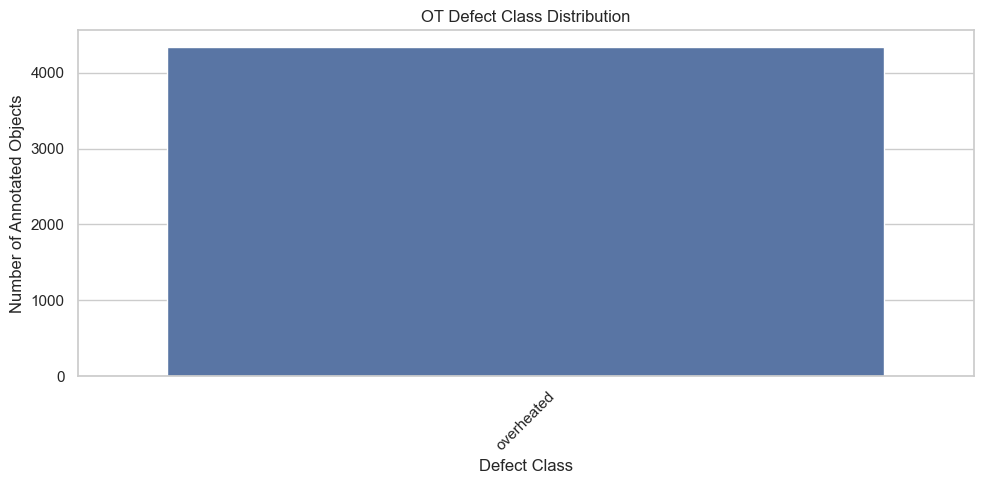

In [5]:
class_counts = ot_annotations["class_name"].value_counts()

print("Defect class counts:")
display(class_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("OT Defect Class Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Number of Annotated Objects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Images with annotations: 1122

Defects per image summary:


count    1122.000000
mean        3.867201
std         2.096514
min         1.000000
25%         3.000000
50%         3.000000
75%         4.750000
max        25.000000
Name: defect_count, dtype: float64

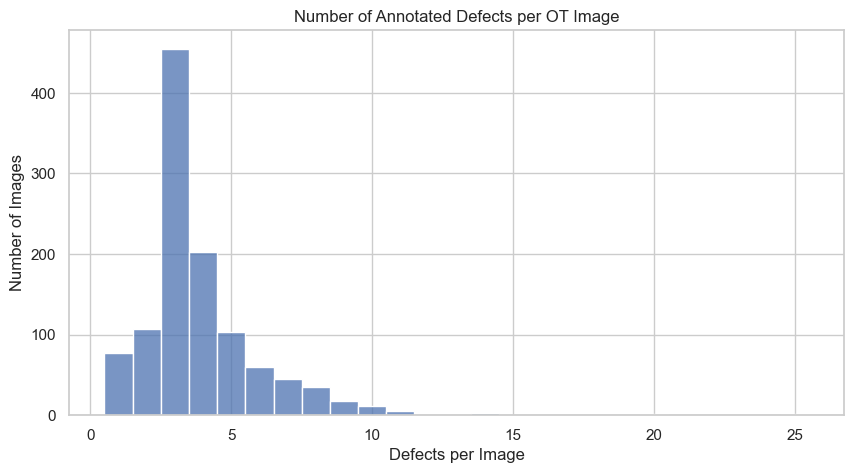

In [6]:
ot_defects_per_image = (
    ot_annotations.groupby("image_filename")
    .size()
    .reset_index(name="defect_count")
)

print("Images with annotations:", len(ot_defects_per_image))
print("\nDefects per image summary:")
display(ot_defects_per_image["defect_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(
    ot_defects_per_image["defect_count"],
    bins=range(1, ot_defects_per_image["defect_count"].max() + 2),
    discrete=True
)

plt.title("Number of Annotated Defects per OT Image")
plt.xlabel("Defects per Image")
plt.ylabel("Number of Images")
plt.show()

In [7]:
ot_image_stems = {file.stem for file in OT_PATH.glob("*.jpg")}
ot_xml_stems = {file.stem for file in OT_LABEL_PATH.glob("*.xml")}

print("OT images without XML:", len(ot_image_stems - ot_xml_stems))
print("XML files without matching OT image:", len(ot_xml_stems - ot_image_stems))

print("\nExamples of OT images without XML:")
print(list(ot_image_stems - ot_xml_stems)[:10])

print("\nExamples of XML files without matching image:")
print(list(ot_xml_stems - ot_image_stems)[:10])

OT images without XML: 1550
XML files without matching OT image: 0

Examples of OT images without XML:
['SI383820211201123521_58_001_720_Int_32F', 'SI383820240226095904_58_001_180_Int_32F', 'SI383820240318120348_56_002_140_Int_32F', 'SI383820211201123521_685_026_800_Int_32F', 'SI383820240226095904_67_001_360_Int_32F', 'SI383820240318120348_229_005_600_Int_32F', 'SI383820211201123521_539_020_960_Int_32F', 'SI383820240318120348_86_002_740_Int_32F', 'SI383820240318120348_371_008_440_Int_32F', 'SI383820240318120348_311_007_240_Int_32F']

Examples of XML files without matching image:
[]


In [8]:
ot_annotations["bbox_width"] = (
    ot_annotations["xmax"] - ot_annotations["xmin"]
)

ot_annotations["bbox_height"] = (
    ot_annotations["ymax"] - ot_annotations["ymin"]
)

ot_annotations["bbox_area"] = (
    ot_annotations["bbox_width"] * ot_annotations["bbox_height"]
)

ot_annotations["bbox_center_x"] = (
    ot_annotations["xmin"] + ot_annotations["xmax"]
) / 2

ot_annotations["bbox_center_y"] = (
    ot_annotations["ymin"] + ot_annotations["ymax"]
) / 2

ot_annotations[
    ["class_name", "bbox_width", "bbox_height", "bbox_area"]
].describe()

,bbox_width,bbox_height,bbox_area
count,4339.000000,4339.000000,4339.000000
mean,132.370362,119.730122,23885.406776
std,99.269345,98.151306,26796.644962
min,4.000000,6.000000,24.000000
25%,30.000000,28.000000,1032.000000
50%,110.000000,73.000000,6909.000000
75%,240.500000,234.000000,53801.500000
max,445.000000,449.000000,76422.000000


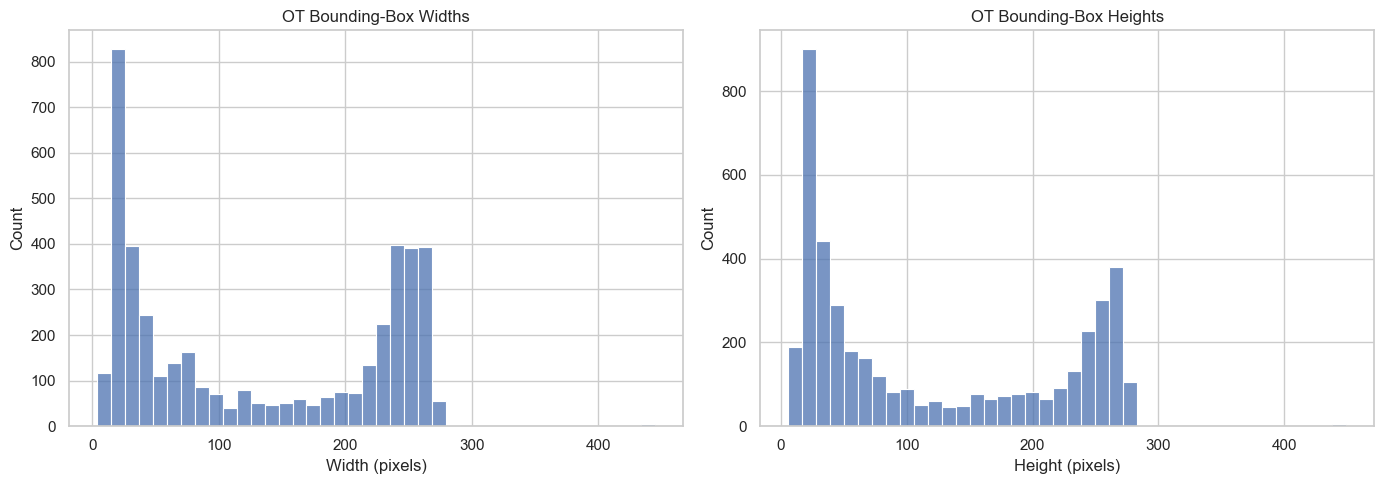

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    ot_annotations["bbox_width"],
    bins=40,
    ax=axes[0]
)
axes[0].set_title("OT Bounding-Box Widths")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(
    ot_annotations["bbox_height"],
    bins=40,
    ax=axes[1]
)
axes[1].set_title("OT Bounding-Box Heights")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

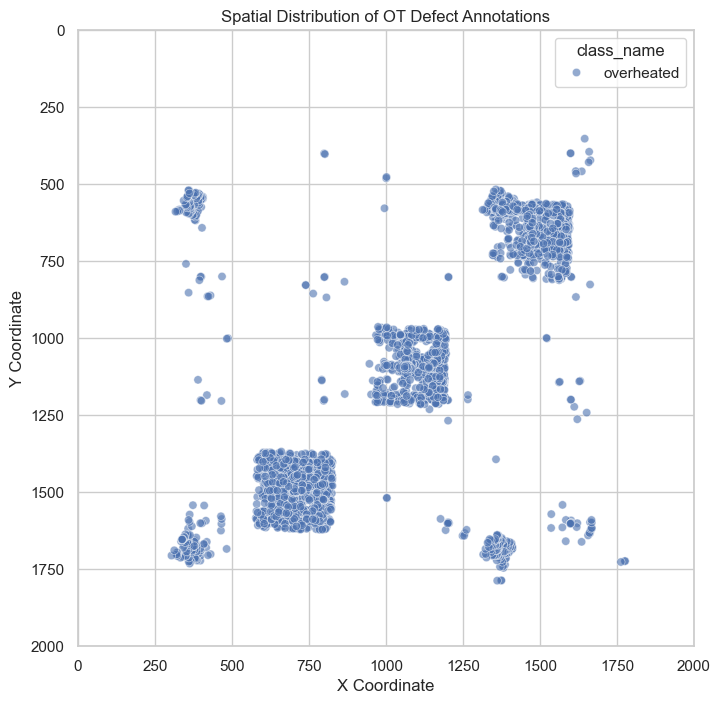

In [10]:
plt.figure(figsize=(8, 8))

sns.scatterplot(
    data=ot_annotations,
    x="bbox_center_x",
    y="bbox_center_y",
    hue="class_name",
    alpha=0.6
)

plt.xlim(0, 2000)
plt.ylim(2000, 0)
plt.title("Spatial Distribution of OT Defect Annotations")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.gca().set_aspect("equal")
plt.show()

In [11]:
invalid_boxes = ot_annotations[
    (ot_annotations["xmin"] < 0) |
    (ot_annotations["ymin"] < 0) |
    (ot_annotations["xmax"] > ot_annotations["width"]) |
    (ot_annotations["ymax"] > ot_annotations["height"]) |
    (ot_annotations["xmax"] <= ot_annotations["xmin"]) |
    (ot_annotations["ymax"] <= ot_annotations["ymin"])
]

print("Invalid bounding boxes:", len(invalid_boxes))
display(invalid_boxes)

Invalid bounding boxes: 0


,xml_filename,image_filename,width,height,class_name,xmin,ymin,xmax,ymax,bbox_width,bbox_height,bbox_area,bbox_center_x,bbox_center_y


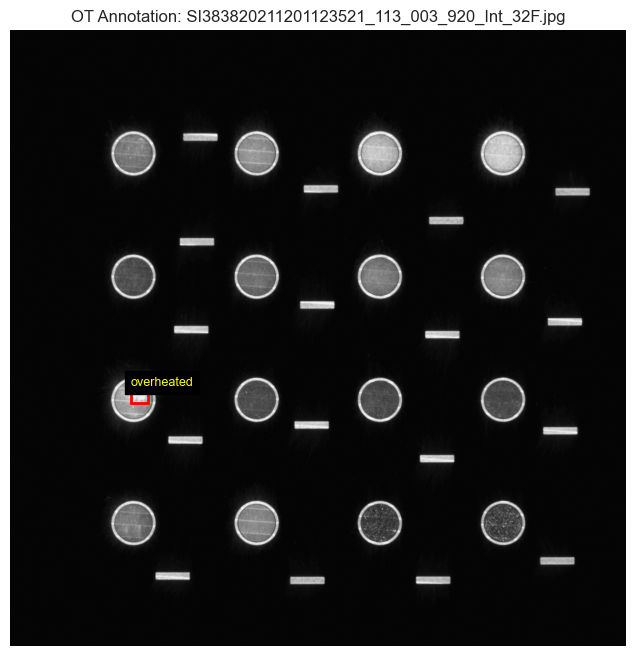

In [14]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Select the first annotation
sample_row = ot_annotations.iloc[0]
sample_image_path = OT_PATH / sample_row["image_filename"]

image = np.array(Image.open(sample_image_path).convert("L"))

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image, cmap="gray")

# Draw every bounding box belonging to this image
image_annotations = ot_annotations[
    ot_annotations["image_filename"] == sample_row["image_filename"]
]

for _, row in image_annotations.iterrows():
    rect = patches.Rectangle(
        (row["xmin"], row["ymin"]),
        row["bbox_width"],
        row["bbox_height"],
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(
        row["xmin"],
        row["ymin"] - 5,
        row["class_name"],
        color="yellow",
        fontsize=9,
        backgroundcolor="black"
    )

ax.set_title(f"OT Annotation: {sample_row['image_filename']}")
ax.axis("off")
plt.show()

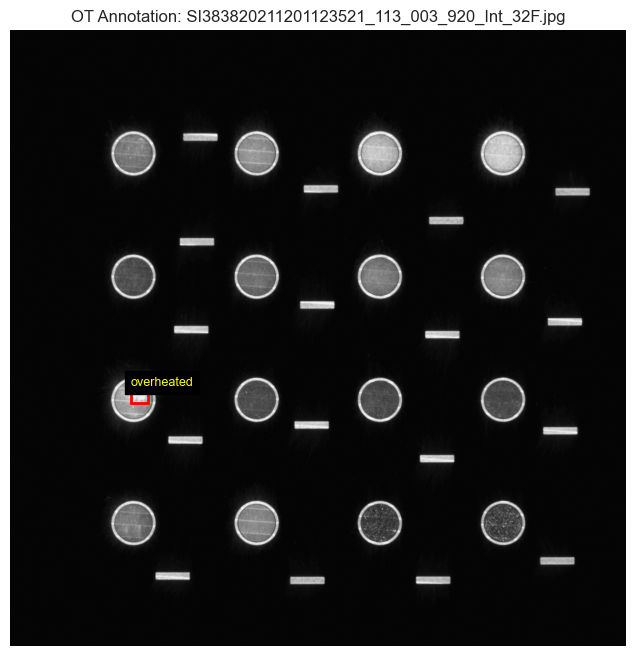

In [15]:
import matplotlib.patches as patches

# Select the first annotation
sample_row = ot_annotations.iloc[0]
sample_image_path = OT_PATH / sample_row["image_filename"]

image = np.array(Image.open(sample_image_path).convert("L"))

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image, cmap="gray")

# Draw every bounding box belonging to this image
image_annotations = ot_annotations[
    ot_annotations["image_filename"] == sample_row["image_filename"]
]

for _, row in image_annotations.iterrows():
    rect = patches.Rectangle(
        (row["xmin"], row["ymin"]),
        row["bbox_width"],
        row["bbox_height"],
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(
        row["xmin"],
        row["ymin"] - 5,
        row["class_name"],
        color="yellow",
        fontsize=9,
        backgroundcolor="black"
    )

ax.set_title(f"OT Annotation: {sample_row['image_filename']}")
ax.axis("off")
plt.show()

In [16]:
OUTPUT_PATH = Path("outputs")
OUTPUT_PATH.mkdir(exist_ok=True)

ot_annotations.to_csv(
    OUTPUT_PATH / "ot_annotations_parsed.csv",
    index=False
)

ot_defects_per_image.to_csv(
    OUTPUT_PATH / "ot_defects_per_image.csv",
    index=False
)

class_counts.rename("count").to_csv(
    OUTPUT_PATH / "ot_defect_class_counts.csv"
)

invalid_boxes.to_csv(
    OUTPUT_PATH / "ot_invalid_bounding_boxes.csv",
    index=False
)

print("OT annotation results saved to:", OUTPUT_PATH.resolve())

OT annotation results saved to: D:\Capstone\metal additive manufacturing\EDA\outputs
